# 11 · Robustness: original vs modified URLs (Milestone 7)

The test split tells us how well a model does on URLs *like the ones it was trained on*. Here we ask two harder questions, **without retraining** any model:

1. **Evasion:** if an attacker makes a cheap, realistic change to a phishing URL, is it still caught?
2. **False alarms:** does a legitimate site get flagged just because it looks a bit different from PhiUSIIL's legitimate URLs (e.g. it has a subdomain)? We test this on PhiUSIIL **and on 30,000 popular real websites** (Chrome UX Report, Tranco).

An independent audit (ollivianguy, `docs/references.md`) already showed that a **raw-URL** model is easy to evade: switching to HTTPS dropped detection from 99.4% to 67.7%. We reproduce that with our raw-URL model, then focus on what they didn't test: **edits to the domain**, aimed at our shortcut-reduced domain-only models, and **legitimate subdomains**.

Edits: `src/phishguard/robustness.py` (each has a unit test). Models: the seed-42 split, threshold chosen on validation as always.

In [1]:
# Import phishguard.deep first: on macOS it makes torch and xgboost share CPU threads safely.
from phishguard.deep import CharURLClassifier
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET, REPO_ROOT
from phishguard.urls import URL_VIEWS, TLD_EXTRACT
from phishguard.features import extract_features
from phishguard.split import get_splits, site_owner
from phishguard.evaluate import evaluate, best_threshold
from phishguard.experiment import load_record
from phishguard.explain import char_occlusion, explain_url, highlight
from phishguard.robustness import PHISHING_EDITS, LEGIT_SUBDOMAINS, add_subdomain, https_www_root, switch_to_https

df = load_clean()
y = df[TARGET]
train_idx, val_idx, test_idx = get_splits(df, seed=42)
domain = URL_VIEWS["domain only"](df["URL"])

## 1. The models (seed-42 split, domain only unless stated)

| Model | Where from |
|---|---|
| Hybrid CNN + features | the saved model from notebook 10 (`models/hybrid_domain_only.pt`) |
| Char-CNN | retrained with the dropout it chose on seed 42 (notebook 08) |
| Char n-gram LogReg | retrained with the `C` it chose on seed 42 (notebook 07) |
| XGBoost (URL features) | retrained, `max_depth=6` (notebook 07) |
| Char n-gram LogReg, **raw URL** | only for Part A, to compare with the audit |

Each model is wrapped as "list of inputs → P(phishing)", with its threshold chosen on validation.

In [2]:
def make_ngram(C):
    return make_pipeline(TfidfVectorizer(analyzer="char", ngram_range=(1, 4), min_df=2, sublinear_tf=True, dtype=np.float32),
                         LogisticRegression(C=C, solver="liblinear", max_iter=3000))

def seed42_params(group, name):
    return load_record(group, name)["reference"]["params"]

hybrid = CharURLClassifier.load(REPO_ROOT / "models" / "hybrid_domain_only.pt")
cnn = CharURLClassifier(arch="cnn", **seed42_params("m4_deep", "Char-CNN | domain only")).fit(
    domain.loc[train_idx], y.loc[train_idx])
ngram = make_ngram(**seed42_params("m3_views", "Char n-gram LogReg | domain only")).fit(domain.loc[train_idx], y.loc[train_idx])
xgb = XGBClassifier(max_depth=6, n_estimators=500, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                    random_state=42).fit(extract_features(domain.loc[train_idx]), y.loc[train_idx])
raw_ngram = make_ngram(**seed42_params("m3_views", "Char n-gram LogReg | raw URL")).fit(df.loc[train_idx, "URL"], y.loc[train_idx])

predict = {   # each takes a Series of domains and returns P(phishing)
    "Hybrid": lambda d: hybrid.predict_proba(extract_features(d).assign(url=d.to_numpy()))[:, 1],
    "Char-CNN": lambda d: cnn.predict_proba(d)[:, 1],
    "n-gram": lambda d: ngram.predict_proba(d)[:, 1],
    "XGBoost (features)": lambda d: xgb.predict_proba(extract_features(d))[:, 1],
}
MODELS = list(predict)
threshold = {name: best_threshold(y.loc[val_idx], f(domain.loc[val_idx])) for name, f in predict.items()}
threshold["Hybrid"] = json.loads((REPO_ROOT / "models" / "hybrid_domain_only.json").read_text())["threshold"]
raw_threshold = best_threshold(y.loc[val_idx], raw_ngram.predict_proba(df.loc[val_idx, "URL"])[:, 1])

yt = y.loc[test_idx]
check = {name: evaluate(yt, f(domain.loc[test_idx]), threshold[name]) for name, f in predict.items()}
check["n-gram, raw URL"] = evaluate(yt, raw_ngram.predict_proba(df.loc[test_idx, "URL"])[:, 1], raw_threshold)
pd.DataFrame(check).loc[["accuracy", "recall", "precision", "roc_auc"]].T.assign(
    threshold={**threshold, "n-gram, raw URL": raw_threshold}).round(4)

,accuracy,recall,precision,roc_auc,threshold
Hybrid,0.8778,0.7569,0.9439,0.9238,0.54
Char-CNN,0.8771,0.7442,0.9566,0.9216,0.56
n-gram,0.8733,0.7591,0.9293,0.9213,0.52
XGBoost (features),0.8019,0.6082,0.8902,0.8455,0.44
"n-gram, raw URL",0.9975,0.9947,0.9995,0.9987,0.20


These match the seed-42 results of notebooks 07–09, so the models are the ones we evaluated.

## Part A · Raw-URL attack (reproducing the audit)

Phishing URLs from the test split, edited the way the audit did:
- **switch to HTTPS**: `http://…` → `https://…`, for every URL;
- **look like PhiUSIIL's legitimate URLs**: `https://www.<host>` with no path or query, only for hosts the attacker controls (not on a hosting platform).

The domain-only models can't see the scheme, `www.` or the path, so these edits leave their input **unchanged**. We check that explicitly.

In [3]:
phish_urls = df.loc[test_idx, "URL"][yt == 1]
rows = []
for edit_name, edit in {"switch to HTTPS": switch_to_https, "https://www. + no path": https_www_root}.items():
    edited = phish_urls.map(edit).dropna()
    original = phish_urls.loc[edited.index]
    before = raw_ngram.predict_proba(original)[:, 1] >= raw_threshold
    after = raw_ngram.predict_proba(edited)[:, 1] >= raw_threshold
    same_domain = (URL_VIEWS["domain only"](edited) == URL_VIEWS["domain only"](original)).mean()
    rows.append({"edit": edit_name, "phishing URLs edited": len(edited),
                 "raw-URL n-gram: caught before": before.mean(), "caught after": after.mean(),
                 "domain-only input unchanged": same_domain})
pd.DataFrame(rows).round(4)

,edit,phishing URLs edited,raw-URL n-gram: caught before,caught after,domain-only input unchanged
0,switch to HTTPS,7771,1.0000,0.3554,1.0
1,https://www. + no path,11112,0.9996,0.1776,1.0


## Part B · Domain edits an attacker could make (distinct phishing test domains)

Every edit applies only where it makes sense: no `.com` swap for a domain on a hosting platform, no subdomain to drop if there is none, and so on. For each edit we compare the **same** domains before and after. Each distinct domain counts once, so a few frequent hosts (like `ipfs.io`) don't dominate.

In [4]:
phish_domains = pd.Series(domain.loc[test_idx][yt == 1].unique())
legit_domains = pd.Series(domain.loc[test_idx][yt == 0].unique())
print(f"distinct test domains: {len(phish_domains):,} phishing, {len(legit_domains):,} legitimate")

def detection(domains):
    return {name: (f(domains) >= threshold[name]) for name, f in predict.items()}

rows, edited_sets = [], {}
for edit_name, edit in PHISHING_EDITS.items():
    edited = phish_domains.map(edit)
    mask = edited.notna()
    original, after_edit = phish_domains[mask].reset_index(drop=True), edited[mask].reset_index(drop=True)
    edited_sets[edit_name] = (original, after_edit)
    before, after = detection(original), detection(after_edit)
    row = {"edit": edit_name, "domains it applies to": int(mask.sum()), "example": f"{original[0]} → {after_edit[0]}"}
    for name in MODELS:
        row[name] = f"{before[name].mean():.1%} → {after[name].mean():.1%}"
    rows.append(row)
evasion = pd.DataFrame(rows).set_index("edit")
evasion

distinct test domains: 11,612 phishing, 20,225 legitimate


,domains it applies to,example,Hybrid,Char-CNN,n-gram,XGBoost (features)
edit,,,,,,
TLD → .com,4258,ipfs.io → ipfs.com,73.8% → 51.3%,71.4% → 47.4%,73.7% → 51.6%,57.2% → 45.2%
drop subdomain,3659,iuhjn.pplink.club → pplink.club,99.2% → 54.0%,97.5% → 55.3%,88.4% → 62.9%,98.3% → 33.6%
remove digits and hyphens,5428,mechinchem-5cb8a.web.app → mechinchemcba.web.app,92.0% → 86.2%,90.2% → 84.6%,92.4% → 83.9%,89.3% → 74.5%
look-alike digits → letters,3597,mechinchem-5cb8a.web.app → mechinchem-scbba.we...,96.7% → 93.3%,95.9% → 92.6%,96.8% → 91.8%,96.9% → 91.0%
leave hosting platform (own .com),3209,mechinchem-5cb8a.web.app → mechinchem-5cb8a.com,99.9% → 71.5%,99.8% → 68.7%,99.8% → 74.8%,100.0% → 56.8%
all of the above,9531,ipfs.io → ipfs.com,85.5% → 19.7%,83.5% → 20.6%,83.4% → 31.9%,77.4% → 3.6%


Read each cell as **share of these phishing domains caught before → after the edit**.

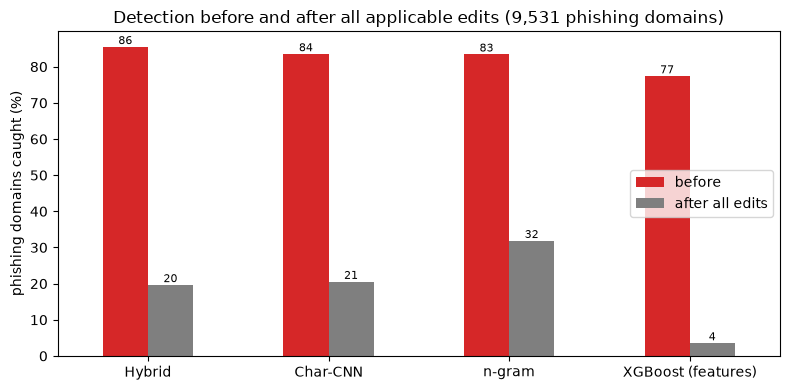

In [5]:
original, after_edit = edited_sets["all of the above"]
before, after = detection(original), detection(after_edit)
summary = pd.DataFrame({"before": {m: before[m].mean() for m in MODELS}, "after all edits": {m: after[m].mean() for m in MODELS}}) * 100
ax = summary.plot.bar(rot=0, figsize=(8, 4), color=["tab:red", "tab:gray"])
ax.set_ylabel("phishing domains caught (%)")
ax.set_title(f"Detection before and after all applicable edits ({len(original):,} phishing domains)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8)
plt.tight_layout()
plt.show()

## Part C · Legitimate domains with a subdomain (distinct legitimate test domains)

Only ~6% of PhiUSIIL's legitimate domains have any subdomain (notebook 07). Real legitimate sites often do (`mail.`, `blog.`, `accounts.` …). We add one such subdomain to every legitimate test domain and measure the **false-alarm rate** (legitimate flagged as phishing).

In [6]:
rows = [{"subdomain added": "(none: original)", **{m: (f(legit_domains) >= threshold[m]).mean() for m, f in predict.items()}}]
for prefix in LEGIT_SUBDOMAINS:
    edited = legit_domains.map(lambda d: add_subdomain(d, prefix)).dropna()
    rows.append({"subdomain added": f"{prefix}.", **{m: (f(edited) >= threshold[m]).mean() for m, f in predict.items()}})
false_alarms = pd.DataFrame(rows).set_index("subdomain added")
(false_alarms * 100).round(1).astype(str) + "%" 

,Hybrid,Char-CNN,n-gram,XGBoost (features)
subdomain added,,,,
(none: original),3.3%,2.5%,4.3%,5.5%
www2.,94.6%,86.3%,71.6%,99.4%
mail.,89.2%,81.5%,70.6%,87.5%
blog.,73.8%,46.0%,21.1%,87.6%
shop.,82.0%,60.0%,36.3%,87.7%
login.,95.0%,74.6%,73.4%,96.9%
accounts.,86.2%,75.1%,61.8%,92.7%


## Part D · Popular real websites outside PhiUSIIL

- **CrUX top 10k origins:** the 10,000 most-visited origins in Chrome, *including subdomains* (`DataSets/external/README.md`).
- **Tranco top 20k:** popular registered domains.

We drop every site whose owner (registered domain) appears **anywhere** in PhiUSIIL, so these sites are new to every model. Then we reduce each to the domain-only view and measure how many each model flags. Ideally the answer is ~0%.

In [7]:
external = REPO_ROOT / "DataSets" / "external"
crux = pd.read_csv(external / "crux_top10k_2026-10.csv")
tranco = pd.read_csv(external / "tranco_GQ3QK_top20k.csv")
phiusiil_owners = set(site_owner(df["URL"]))

# Shown examples skip adult sites (they are in the top lists); every count below includes them.
ADULT = r"porn|xhamster|xvideos|xnxx|sex|xxx|hentai|onlyfans|chaturbate|stripchat|redtube|youporn"

def kind(host):
    ext = TLD_EXTRACT(host)
    if ext.is_private:
        return "on a hosting platform"
    return "with a subdomain" if ext.subdomain else "bare domain"

sets = {}
crux_hosts = URL_VIEWS["domain only"](crux["origin"]).drop_duplicates()
crux_hosts = crux_hosts[~site_owner(crux_hosts).isin(phiusiil_owners)]
for group, hosts in crux_hosts.groupby(crux_hosts.map(kind)):
    sets[f"CrUX top 10k: {group}"] = hosts.reset_index(drop=True)
tranco_domains = tranco["domain"].drop_duplicates()
sets["Tranco top 20k: registered domains"] = tranco_domains[~site_owner(tranco_domains).isin(phiusiil_owners)].reset_index(drop=True)

rows = []
for set_name, hosts in sets.items():
    rows.append({"set": set_name, "sites": len(hosts), "example": ", ".join(hosts[~hosts.str.contains(ADULT)].head(3)),
                 **{m: (f(hosts) >= threshold[m]).mean() for m, f in predict.items()}})
real_world = pd.DataFrame(rows).set_index("set")
real_world[MODELS] = (real_world[MODELS] * 100).round(1)
print(f"{len(crux_hosts):,} CrUX hosts and {len(sets['Tranco top 20k: registered domains']):,} Tranco domains not seen in PhiUSIIL")
real_world

8,575 CrUX hosts and 16,840 Tranco domains not seen in PhiUSIIL


,sites,example,Hybrid,Char-CNN,n-gram,XGBoost (features)
set,,,,,,
CrUX top 10k: bare domain,5975,"github.com, amazon.co.jp, amazon.es",15.3,14.1,21.6,13.1
CrUX top 10k: on a hosting platform,16,"universal-credit.service.gov.uk, y2mate.in.net...",75.0,43.8,37.5,93.8
CrUX top 10k: with a subdomain,2584,"m.cricbuzz.com, mail.yahoo.com, m.avito.ru",80.8,68.7,51.8,86.2
Tranco top 20k: registered domains,16840,"cloudflare.com, amazonaws.com, facebook.com",18.8,17.3,26.1,11.3


Columns = **% of these legitimate sites flagged as phishing**. For comparison, the false-alarm rate on PhiUSIIL's own test domains is in the first row of Part C.

**Why are even popular *bare* domains flagged?** We break the hybrid's false alarms on CrUX bare domains down by suffix, next to how often that suffix was phishing in PhiUSIIL's **training** split.

In [8]:
bare = sets["CrUX top 10k: bare domain"]
flagged_bare = pd.Series(predict["Hybrid"](bare) >= threshold["Hybrid"], index=bare.index)
bare_suffix = bare.map(lambda h: TLD_EXTRACT(h).suffix)
train_domains = domain.loc[train_idx]
train_suffix = train_domains.map(lambda h: TLD_EXTRACT(h).suffix)
phishing_share = y.loc[train_idx].groupby(train_suffix.to_numpy()).mean()
legit_count = (y.loc[train_idx] == 0).groupby(train_suffix.to_numpy()).sum()
by_suffix = pd.DataFrame({
    "CrUX bare sites": bare_suffix.value_counts(),
    "flagged by hybrid (%)": flagged_bare.groupby(bare_suffix).mean() * 100,
    "PhiUSIIL train: legitimate rows": legit_count.reindex(bare_suffix.value_counts().index),
    "PhiUSIIL train: phishing share (%)": phishing_share.reindex(bare_suffix.value_counts().index) * 100,
}).rename_axis("suffix").sort_values("CrUX bare sites", ascending=False).head(15)
by_suffix.round(1)

,CrUX bare sites,flagged by hybrid (%),PhiUSIIL train: legitimate rows,PhiUSIIL train: phishing share (%)
suffix,,,,
com,2751,8.8,48266.0,34.1
net,254,15.7,2806.0,41.2
org,134,0.0,11563.0,7.9
jp,123,0.8,400.0,11.9
com.br,116,1.7,657.0,39.7
ru,98,36.7,589.0,79.3
de,95,0.0,2322.0,14.9
fr,85,1.2,929.0,27.8
tv,82,8.5,173.0,14.4


## Part E · Why? Explanations of a few cases (hybrid)

**Evasion:** phishing domains the hybrid caught before but missed after all edits.
**False alarms:** popular real sites with a subdomain that the hybrid flags.

In [9]:
def show(pairs, title):
    lines = []
    for before, after in pairs:
        cells = []
        for text in (before, after):
            if text is None:
                cells.append("<td></td><td></td>")
                continue
            r = explain_url(hybrid, text)
            top = ", ".join(f"{k} {v:+.1f}" for k, v in r["feature_scores"].head(2).items())
            cells.append(f"<td style='text-align:left'>{highlight(r['input'], r['char_scores'])}<br><small>{top}</small></td>"
                         f"<td>{r['probability']:.3f}</td>")
        lines.append("<tr>" + "".join(cells) + "</tr>")
    display(HTML(f"<b>{title}</b><table><tr><th>before</th><th>P</th><th>after</th><th>P</th></tr>" + "".join(lines) + "</table>"))

original, after_edit = edited_sets["all of the above"]
flipped = np.flatnonzero(before["Hybrid"] & ~after["Hybrid"])
show([(original[i], after_edit[i]) for i in np.random.default_rng(0).choice(flipped, min(6, len(flipped)), replace=False)],
     "Phishing domains the hybrid stops catching after the edits")

hosts = sets["CrUX top 10k: with a subdomain"]
flagged = hosts[predict["Hybrid"](hosts) >= threshold["Hybrid"]]
flagged = flagged[~flagged.str.contains(ADULT)]
show([(h, None) for h in flagged.head(8)], "Popular real sites with a subdomain that the hybrid flags as phishing (adult sites not shown)")

before,P,after,P
"modernconstruction.companynum_subdomains -1.0, on_hosting_platform -0.8",0.734,"modernconstruction.comnum_subdomains -0.2, on_hosting_platform -0.2",0.220
"web-a69ee.web.appon_hosting_platform +6.3, special_ratio -1.5",1.000,"webaee.comlongest_token -0.1, url_entropy -0.1",0.221
"fb-metacase158123700441.web.appon_hosting_platform +6.8, host_digits +2.5",1.000,"fbmetacaselsbletooaal.comnum_subdomains -0.4, on_hosting_platform -0.3",0.215
"s.hrbqn.comnum_subdomains +1.5, special_ratio -0.7",0.999,"hrbqn.comnum_subdomains -0.2, longest_token -0.2",0.418
"resultado0730.coophost_digits +1.0, num_subdomains -0.9",0.980,"resultadooteo.comnum_subdomains -0.3, on_hosting_platform -0.1",0.388
"de-wix-com.usrfiles.comnum_subdomains +3.0, special_ratio -1.4",0.991,"usrfiles.comhost_hyphens -0.0, url_length -0.0",0.201


before,P,after,P
"m.cricbuzz.comnum_subdomains +1.1, special_ratio -0.4",0.687,,
"mail.yahoo.comnum_subdomains +2.4, on_hosting_platform -0.6",0.998,,
"m.avito.runum_subdomains +0.7, special_ratio -0.4",0.739,,
"m.betking.comnum_subdomains +2.0, special_ratio -0.6",0.995,,
"cekbansos.kemensos.go.idnum_subdomains +3.0, on_hosting_platform -0.8",0.966,,
"outlook.office365.comnum_subdomains +3.4, host_digits +0.9",1.000,,
"open.spotify.comnum_subdomains +2.3, on_hosting_platform -0.5",0.947,,
"cdn.pla3.comnum_subdomains +1.9, special_ratio -0.7",0.970,,


## What we learned
1. **The raw-URL model is trivially evaded.** Switching phishing URLs from `http` to `https` drops the raw-URL n-gram's detection from 100% to **35.5%**. Making them look like `https://www.<host>` with no path drops it to **17.8%**. That is even worse than the independent audit found (67.7%). The domain-only models are immune to these edits by construction: their input is 100% unchanged.
2. **But cheap domain edits evade the domain-only models too** (distinct phishing test domains, caught before → after):
   - **Dropping the subdomain:** hybrid 99% → 54%.
   - **Moving off a hosting platform to an own `.com`:** 100% → 72%.
   - **`.cf/.top/…` → `.com`:** 74% → 51%.
   - **All edits together:** hybrid 86% → **20%**, n-gram 83% → **32%**, XGBoost 77% → 4%.
   - **Look-alike digits → letters** barely matter (97% → 93%): the models don't rely much on single digits.
3. **Legitimate subdomains are flagged.** Adding `mail.` to PhiUSIIL's own legitimate test domains raises the hybrid's false-alarm rate from 3.3% to **89%** (`blog.` → 74%, `login.` → 95%). The n-gram model is the least affected (`blog.` → 21%), and the feature-based models the most. This is the `num_subdomains` bias found in notebook 10, now measured.
4. **The models don't transfer to the real web.** On popular websites not in PhiUSIIL, the hybrid flags:
   - **15%** of CrUX bare domains;
   - **81%** of CrUX hosts with a subdomain (`mail.yahoo.com` 0.998, `outlook.office365.com` 1.000, `open.spotify.com` 0.947);
   - **19%** of Tranco's top registered domains.
   
   On PhiUSIIL's own test domains it flags 3.3%.
5. **Why popular bare domains are flagged: country priors from how the data was collected.** In PhiUSIIL's training split, 79% of `.ru` and 78% of `.ir` rows are phishing. The hybrid flags 37% of popular `.ru`, 34% of `.ir` and 33% of `.in` sites, but 0% of `.org` and `.de`. The model learned *which countries the phishing feed came from*, not only what phishing looks like.
6. **Which model is most robust?** None is robust, and it depends on the threat:
   - Against **edits and subdomains**, the **n-gram model** holds up best: it keeps the most phishing after all edits (32%) and raises the fewest false alarms on CrUX subdomains (52% vs 81% for the hybrid).
   - On popular **bare** domains it raises *more* false alarms than the hybrid (22% vs 15%; Tranco 26% vs 19%). XGBoost raises the fewest there (13%; Tranco 11%), but it is the easiest to evade (4% caught after all edits).
   
   The hybrid's advantage on the test split (Milestone 5) comes partly from the features `num_subdomains` and `on_hosting_platform`, which are exactly what these edits and real subdomains break.
7. **Bottom line for the report and the app:** within PhiUSIIL the domain-only models reach ~88% accuracy (ROC-AUC 0.92). Outside it, they would flag about 1 in 6 popular plain domains and most sites with a subdomain, and a cheap `.com` domain evades them. This agrees with the independent audits (`docs/references.md`). The fix is **better data**, with legitimate URLs that look like the real web (subdomains, paths, many countries), not a bigger model. The app (Milestone 8) must show these limits next to every prediction.